<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---------- REGRESSION MODEL COMPARISON ----------
----- Linear Regression -----
Mean Squared Error (MSE) : 813.1848
R-squared (R²) Score      : 0.5251
---------------------------------------------
----- Polynomial Regression (Degree 3) -----
Mean Squared Error (MSE) : 7.5700
R-squared (R²) Score      : 0.9956


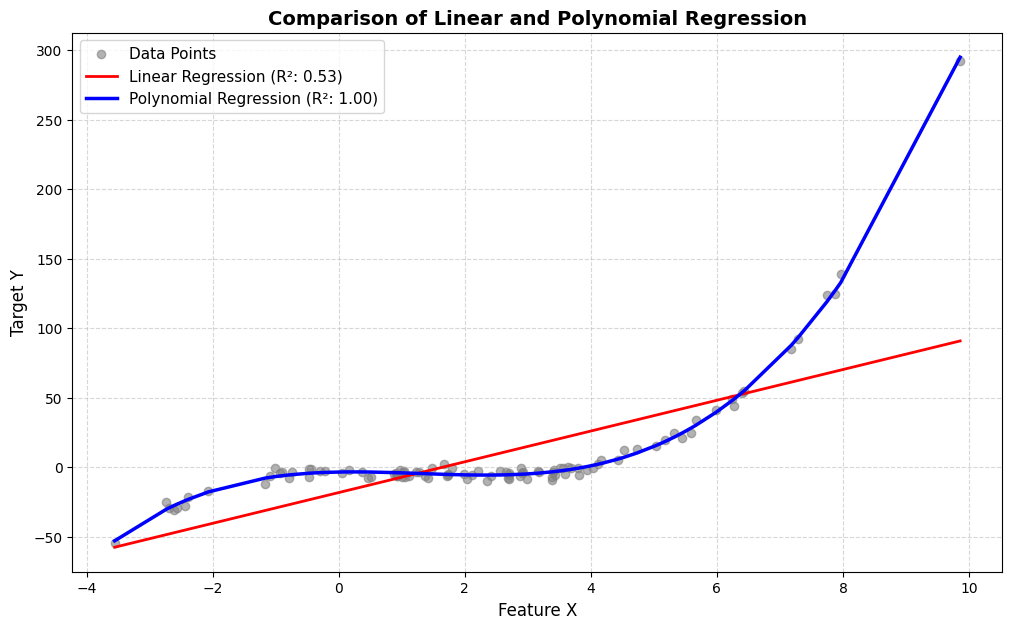

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# 1. Generate Synthetic Non-Linear Data
np.random.seed(42)
x = 2 - 3 * np.random.normal(0, 1, 100)
y = x - 2 * (x ** 2) + 0.5 * (x ** 3) + np.random.normal(-3, 3, 100)

# Reshaping for sklearn
x = x[:, np.newaxis]

# Sort data points for plotting curves smoothly
sort_axis = np.argsort(x, axis=0)
x_sorted = x[sort_axis].reshape(-1, 1)
y_sorted = y[sort_axis]

# 2. Fit Linear Regression Model
linear_model = LinearRegression()
linear_model.fit(x, y)
y_pred_linear = linear_model.predict(x_sorted)

# 3. Fit Polynomial Regression Model (Degree = 3)
poly_features = PolynomialFeatures(degree=3)
x_poly = poly_features.fit_transform(x)

poly_model = LinearRegression()
poly_model.fit(x_poly, y)

# Predict on sorted data
x_poly_sorted = poly_features.transform(x_sorted)
y_pred_poly = poly_model.predict(x_poly_sorted)

# 4. Calculate Metrics
# Evaluating on original points to get true score
y_pred_linear_all = linear_model.predict(x)
y_pred_poly_all = poly_model.predict(poly_features.transform(x))

mse_linear = mean_squared_error(y, y_pred_linear_all)
r2_linear = r2_score(y, y_pred_linear_all)

mse_poly = mean_squared_error(y, y_pred_poly_all)
r2_poly = r2_score(y, y_pred_poly_all)

# 5. Presentable Output
print("="*45)
print(f"{'-'*10} REGRESSION MODEL COMPARISON {'-'*10}")
print("="*45)
print(f"{'-'*5} Linear Regression {'-'*5}")
print(f"Mean Squared Error (MSE) : {mse_linear:.4f}")
print(f"R-squared (R²) Score      : {r2_linear:.4f}")
print("-"*45)
print(f"{'-'*5} Polynomial Regression (Degree 3) {'-'*5}")
print(f"Mean Squared Error (MSE) : {mse_poly:.4f}")
print(f"R-squared (R²) Score      : {r2_poly:.4f}")
print("="*45)

# 6. Visualization
plt.figure(figsize=(12, 7))
plt.scatter(x, y, color='gray', alpha=0.6, label='Data Points')
plt.plot(x_sorted, y_pred_linear, color='red', linewidth=2, label=f'Linear Regression (R²: {r2_linear:.2f})')
plt.plot(x_sorted, y_pred_poly, color='blue', linewidth=2.5, label=f'Polynomial Regression (R²: {r2_poly:.2f})')
plt.title('Comparison of Linear and Polynomial Regression', fontsize=14, fontweight='bold')
plt.xlabel('Feature X', fontsize=12)
plt.ylabel('Target Y', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()